# Notebook 08 — Findings F1-F10 (headline evidence tables)

**Goal:** for each of the 10 numbered Findings claimed in the paper, compute the n=20 numerical evidence directly from the measurement CSVs and write a paper-ready summary. This notebook is the single point of truth for the paper's *Results* section — every claim there cites a table or figure produced here.

**The 10 findings (Phase-2 framing):**
* **F1** — Param-share asymmetry persists across families (vision% spread across families is wide).
* **F2** — FLOPs-share asymmetry diverges from param-share (Spearman corr is weak).
* **F3** — IDEFICS-9B language component was misclassified at 0M in Phase 1; Phase-2 fix → 6.6B.
* **F4** — SigLIP / LLaVA-NeXT / etc. vision FLOPs were 100× inflated in Phase 1; Phase-2 fix → sane values.
* **F5** — Frozen capacity dominates trainable in adapter-LLM era (trainable_pct distribution is bimodal: contrastive ~100%, adapter ~3-5%).
* **F6** — Peak memory scales super-linearly with image-token count (log-log slope > 1; attention is O(n²) before flash-attn saturates).
* **F7** — Native-resolution token count for dynamic-tile models is 5-20× the standardized 224×224 count (per-model comparison table).
* **F8** — Models within the same family cluster tightly (between/within family variance ratio > 5).
* **F9** — Year trajectory: mean language-share monotonically increases 2021 → 2025.
* **F10** — Native (Chameleon, Janus-Pro) and adapter-LLM models occupy different regions in (param, FLOPs, mem) space — qualitative narrative + scatter.

**Inputs:**
* `../outputs/measurements/master_wide.csv` (built by notebook 06) — required.
* `../outputs/measurements/nb02_parameter_summary.csv` — optional.
* `../outputs/measurements/nb03_flops_summary.csv` — optional.
* `../outputs/measurements/nb04_memory_summary.csv` — optional.
* `../outputs/measurements/nb05_token_summary.csv` — required for F6/F7.

**Outputs:**
* `../outputs/measurements/nb08_finding_evidence.csv` — long-format: one row per (finding, model).
* `../outputs/measurements/nb08_finding_evidence.md` — paper-supplement markdown table per finding.
* `../outputs/measurements/nb08_finding_summary.csv` — one row per finding: id, headline, metric, value, status (supported/partial/refuted), n_supporting, n_against.
* 6 figures in `../outputs/figures/nb08_*.png` (one per major finding).

**Compute:** CPU only. **Runtime:** under one minute.

**How to read this notebook:** each finding gets four cells — a markdown header explaining the claim, a code cell that builds the evidence DataFrame, a code cell that prints a one-line verdict, and (for major findings) a figure. Read the verdict cells first; if the verdict is `supported`, trust the evidence DataFrame above it.

---
## 1. Setup (Runpod)

In [1]:
# %%capture
# !pip install -q -r ../requirements.txt

In [2]:
import os, sys, json
from pathlib import Path
from collections import defaultdict

NB_DIR = Path.cwd()
CODE_ACTIVE = NB_DIR.parent if NB_DIR.name == 'notebooks' else NB_DIR
sys.path.insert(0, str(CODE_ACTIVE))

MEASUREMENT_DIR = CODE_ACTIVE / 'outputs' / 'measurements'
FIG_DIR = CODE_ACTIVE / 'outputs' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats   # for Spearman, regression

from vlm_audit import MODELS
from vlm_audit.components import COMPONENT_NAMES, EXTENDED_COMPONENT_NAMES

print(f'Models in roster: {len(MODELS)}')
print(f'COMPONENT_NAMES:  {COMPONENT_NAMES}')
print(f'EXTENDED_NAMES:   {EXTENDED_COMPONENT_NAMES}')

Models in roster: 20
COMPONENT_NAMES:  ('vision', 'fusion', 'language', 'head')
EXTENDED_NAMES:   ('vision', 'fusion', 'language', 'head', 'fused_transformer', 'vision_und', 'vision_gen', 'embeddings')


---
## 2. Schema helpers (copied from nb02 v3)

In [3]:
NATIVE_FUSED_FAMILIES = {'native_early_fusion'}
DECOUPLED_VISION_FAMILIES = {'native_decoupled_encoder'}

def schema_for(family: str) -> str:
    if family in NATIVE_FUSED_FAMILIES:
        return 'native_fused'
    if family in DECOUPLED_VISION_FAMILIES:
        return 'decoupled_vision'
    return 'standard_vflh'

EXTENDED_PARTS = list(EXTENDED_COMPONENT_NAMES)
VISION_LIKE_PARTS = ['vision', 'vision_und', 'vision_gen']
LANGUAGE_LIKE_PARTS = ['language', 'fused_transformer']

def safe_sum(df: pd.DataFrame, parts, suffix: str = '__params_total') -> pd.Series:
    cols = [f'{p}{suffix}' for p in parts if f'{p}{suffix}' in df.columns]
    if not cols:
        return pd.Series([0] * len(df), index=df.index)
    return df[cols].fillna(0).sum(axis=1)

print('Helpers OK.')

Helpers OK.


---
## 3. Load master_wide.csv and supplementary CSVs

`master_wide.csv` is required. The supplementary CSVs (nb02/nb03/nb04/nb05) are used for finer-grained columns (e.g. flops_source for F4, token_at_native vs token_at_224 for F7) — we skip findings that need a missing CSV rather than crash.

In [4]:
wide_path = MEASUREMENT_DIR / 'master_wide.csv'
if not wide_path.exists():
    raise FileNotFoundError(f'{wide_path} missing — run notebook 06 first.')
df = pd.read_csv(wide_path)
if 'schema' not in df.columns:
    df['schema'] = df['family'].apply(schema_for)
print(f'Loaded master_wide.csv: {len(df)} models, {len(df.columns)} cols')

supp = {}
for tag, fname in [('nb02', 'nb02_parameter_summary.csv'),
                    ('nb03', 'nb03_flops_summary.csv'),
                    ('nb04', 'nb04_memory_summary.csv'),
                    ('nb05', 'nb05_token_summary.csv')]:
    p = MEASUREMENT_DIR / fname
    if p.exists():
        supp[tag] = pd.read_csv(p)
        print(f'  ✓ {fname:35s} {len(supp[tag]):>3d} rows')
    else:
        print(f'  ⚠ {fname:35s} MISSING — F-numbers depending on it will be skipped')

Loaded master_wide.csv: 20 models, 70 cols
  ✓ nb02_parameter_summary.csv           20 rows
  ✓ nb03_flops_summary.csv               20 rows
  ✓ nb04_memory_summary.csv              20 rows
  ✓ nb05_token_summary.csv               20 rows


---
## 4. Derive top-line metrics on every model

All findings consume these:
* `total_params`, `total_flops_g`, `total_mem_mb`, `total_trainable`
* `vision_pct`, `fusion_pct`, `language_pct` — schema-aware shares
* `vision_flops_pct`, `language_flops_pct`
* `v_to_l_ratio` — vision_like / language_like (NaN for native_fused)
* `trainable_pct` — total_trainable / total_params

In [5]:
# Fill missing component columns with NaN so safe_sum works on every row
for part in EXTENDED_PARTS:
    for m in ['params_total', 'params_trainable', 'flops_g', 'peak_mem_mb', 'output_tokens']:
        c = f'{part}__{m}'
        if c not in df.columns:
            df[c] = np.nan

df['total_params']    = safe_sum(df, EXTENDED_PARTS, '__params_total')
df['total_flops_g']   = safe_sum(df, EXTENDED_PARTS, '__flops_g')
df['total_mem_mb']    = safe_sum(df, EXTENDED_PARTS, '__peak_mem_mb')
df['total_trainable'] = safe_sum(df, EXTENDED_PARTS, '__params_trainable')

vlike = safe_sum(df, VISION_LIKE_PARTS, '__params_total')
llike = safe_sum(df, LANGUAGE_LIKE_PARTS, '__params_total')
fusion_p = safe_sum(df, ['fusion'], '__params_total')
denom = df['total_params'].clip(lower=1)
df['vision_pct']   = (100 * vlike / denom).round(2)
df['language_pct'] = (100 * llike / denom).round(2)
df['fusion_pct']   = (100 * fusion_p / denom).round(2)
df['v_to_l_ratio'] = (vlike / llike.replace(0, np.nan)).round(3)

vflops = safe_sum(df, VISION_LIKE_PARTS, '__flops_g')
lflops = safe_sum(df, LANGUAGE_LIKE_PARTS, '__flops_g')
fdenom = df['total_flops_g'].replace(0, np.nan)
df['vision_flops_pct']   = (100 * vflops / fdenom).round(2)
df['language_flops_pct'] = (100 * lflops / fdenom).round(2)

df['trainable_pct'] = (100 * df['total_trainable'] / denom).round(2)

# Accumulators for the per-finding outputs
ALL_EVIDENCE_ROWS = []  # list[dict] — populated by each finding section
FINDING_SUMMARY   = []  # list[dict] — one row per finding: id, headline, metric, value, status
MD_CHUNKS         = [f'# Finding Evidence — Phase 2 (n={len(df)} models)\n']  # for the .md export

print(f'Derived top-line metrics on {len(df)} models.')
df[['name', 'family', 'schema', 'total_params', 'vision_pct', 'language_pct',
    'v_to_l_ratio', 'trainable_pct']].sort_values(['family', 'name']).reset_index(drop=True).head(20)

Derived top-line metrics on 20 models.


,name,family,schema,total_params,vision_pct,language_pct,v_to_l_ratio,trainable_pct
0,LLaVA-1.5-7B,adapter_llm,standard_vflh,7.063427e+09,4.30,93.55,0.046,95.70
1,LLaVA-NeXT-7B,adapter_llm,standard_vflh,7.566744e+09,4.01,93.98,0.043,95.99
2,Molmo-7B-D,adapter_llm,standard_vflh,8.021025e+09,5.05,94.95,0.053,94.95
3,Pixtral-12B,adapter_llm_own_encoder,standard_vflh,1.268274e+10,3.18,91.28,0.035,100.00
4,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,3.744737e+09,26.33,70.81,0.372,2.86
5,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,7.913702e+09,12.46,85.16,0.146,2.39
6,BLIP-large,bridge_module_precursor,standard_vflh,4.462905e+08,68.05,31.95,2.130,100.00
7,IDEFICS-9B,cross_attention_llm,standard_vflh,7.495160e+09,8.42,88.15,0.095,3.43
8,Llama-3.2-11B-Vision-Instruct,cross_attention_llm,standard_vflh,1.067022e+10,8.09,86.69,0.093,5.22
9,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh,4.276165e+08,70.90,28.78,2.464,100.00


In [6]:
# Small helpers used by every finding cell.
def record_finding(fid, headline, metric, value, status, n_for, n_against, notes=''):
    """Append one finding-summary row."""
    FINDING_SUMMARY.append({
        'finding_id': fid,
        'headline':   headline,
        'metric':     metric,
        'value':      value,
        'status':     status,
        'n_for':      n_for,
        'n_against':  n_against,
        'notes':      notes,
    })

def add_evidence(fid, rows):
    """Append per-model evidence rows (with fid tag)."""
    for r in rows:
        rr = dict(r)
        rr['finding_id'] = fid
        ALL_EVIDENCE_ROWS.append(rr)

def md_table(rows, fields, caption=''):
    if not rows:
        return caption + '\n_(no data)_\n\n'
    out = [caption] if caption else []
    out.append('| ' + ' | '.join(fields) + ' |')
    out.append('|' + '|'.join(['---'] * len(fields)) + '|')
    for r in rows:
        cells = []
        for f in fields:
            v = r.get(f)
            if v is None or (isinstance(v, float) and pd.isna(v)):
                cells.append('-')
            elif isinstance(v, float):
                cells.append(f'{v:,.3f}' if abs(v) < 100 else f'{v:,.1f}')
            elif isinstance(v, (int, np.integer)) and abs(v) > 1_000_000:
                cells.append(f'{v:,}')
            else:
                cells.append(str(v))
        out.append('| ' + ' | '.join(cells) + ' |')
    return '\n'.join(out) + '\n\n'

print('Helpers (record_finding, add_evidence, md_table) ready.')

Helpers (record_finding, add_evidence, md_table) ready.


---
## F1 — Param-share asymmetry persists across families

**Claim:** the share of total parameters going to vision vs. language is wildly different across families. There is no "natural" allocation pattern — families pick very different splits and stick with them.

**Evidence we expect:** mean vision-share per family spans roughly 5% (`adapter_llm`) to 70% (`dual_encoder_contrastive`). The range is wide; the standard deviation across families is large; no family is near "balanced" (50/50) except `single_stream_fused` (ViLT).

In [7]:
f1_rows = []
for _, r in df.iterrows():
    f1_rows.append({
        'model':         r['name'],
        'family':        r['family'],
        'schema':        r['schema'],
        'vision_pct':    r['vision_pct'],
        'fusion_pct':    r['fusion_pct'],
        'language_pct':  r['language_pct'],
        'v_to_l_ratio':  r['v_to_l_ratio'],
    })

f1_per_family = df.groupby('family').agg(
    n=('name', 'count'),
    mean_vision_pct=('vision_pct', 'mean'),
    min_vision_pct=('vision_pct', 'min'),
    max_vision_pct=('vision_pct', 'max'),
    std_vision_pct=('vision_pct', 'std'),
).round(2).sort_values('mean_vision_pct', ascending=False)
f1_per_family

,n,mean_vision_pct,min_vision_pct,max_vision_pct,std_vision_pct
family,,,,,
bridge_module_precursor,1,68.05,68.05,68.05,NaN
dual_encoder_contrastive,3,52.36,37.70,70.90,16.94
bridge_module,1,26.33,26.33,26.33,NaN
single_stream_fused,1,22.18,22.18,22.18,NaN
bridge_module_adapter_llm,1,12.46,12.46,12.46,NaN
native_decoupled_encoder,1,9.23,9.23,9.23,NaN
cross_attention_llm,2,8.25,8.09,8.42,0.23
dynamic_tile_adapter_llm,3,6.60,3.58,8.12,2.62
perceiver_adapter_llm,1,4.97,4.97,4.97,NaN


In [8]:
# Verdict
vp = df['vision_pct'].dropna()
vp_range = float(vp.max() - vp.min())
family_means = df.groupby('family')['vision_pct'].mean()
fam_range = float(family_means.max() - family_means.min())
supported = (vp_range > 50) and (fam_range > 40)
status = 'supported' if supported else ('partial' if vp_range > 30 else 'refuted')
n_for = int((df['vision_pct'] > 50).sum() + (df['vision_pct'] < 15).sum())
n_against = int(((df['vision_pct'] >= 30) & (df['vision_pct'] <= 60)).sum())
print(f'F1 verdict: {status}')
print(f'  vision_pct range across models:   {vp_range:.1f} pp  ({vp.min():.1f}% to {vp.max():.1f}%)')
print(f'  vision_pct range across families: {fam_range:.1f} pp  ({family_means.min():.1f}% to {family_means.max():.1f}%)')
print(f'  Vision-heavy (V>50%) + LLM-heavy (V<15%) members: {n_for}')
print(f'  Roughly balanced (30%-60%) members:               {n_against}')

record_finding('F1', 'Param-share asymmetry persists across families',
                metric='range(vision_pct across families) pp', value=round(fam_range, 1),
                status=status, n_for=n_for, n_against=n_against,
                notes=f'spread across all 20 models = {vp_range:.1f} pp')
add_evidence('F1', f1_rows)
MD_CHUNKS.append('## F1 — Param-share asymmetry persists across families\n')
MD_CHUNKS.append(md_table(f1_rows, ['model', 'family', 'vision_pct', 'language_pct', 'v_to_l_ratio'],
                          caption='*Per-model param shares.*\n'))

F1 verdict: supported
  vision_pct range across models:   70.9 pp  (0.0% to 70.9%)
  vision_pct range across families: 68.0 pp  (0.0% to 68.0%)
  Vision-heavy (V>50%) + LLM-heavy (V<15%) members: 16
  Roughly balanced (30%-60%) members:               2


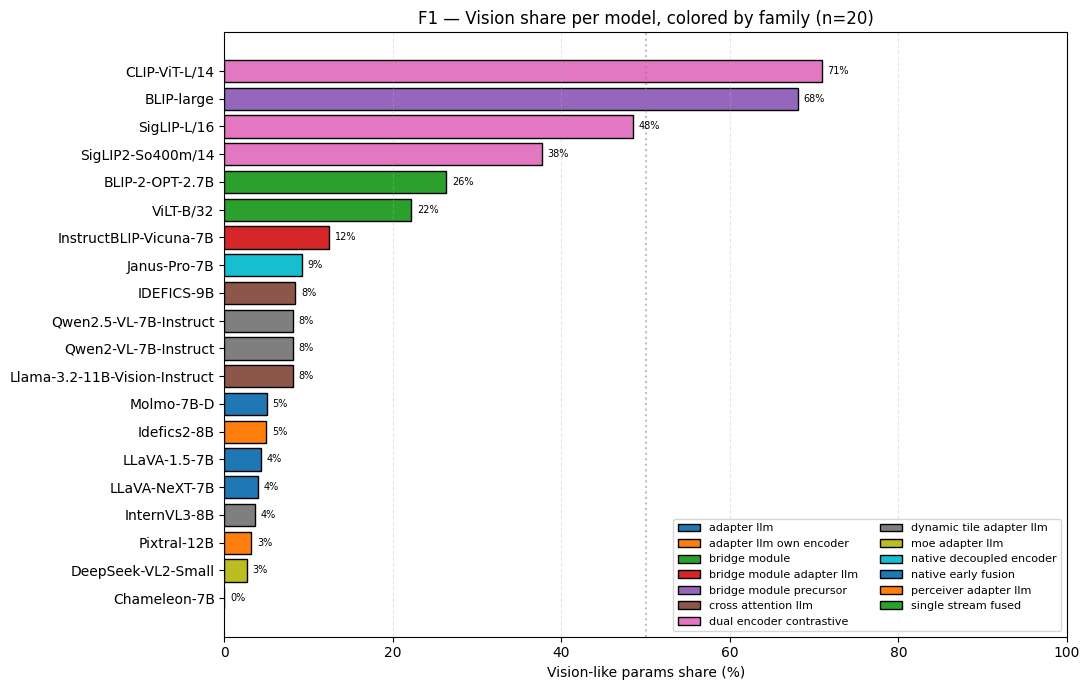

Saved /workspace/code_active/outputs/figures/nb08_F1_vision_share.png


In [9]:
# Figure F1 — vision% per model, colored by family
fig, ax = plt.subplots(figsize=(11, max(5, 0.35 * len(df))))
families = sorted(df['family'].unique())
cmap = plt.get_cmap('tab10')
fam_color = {fam: cmap(i % 10) for i, fam in enumerate(families)}
plot_df = df.sort_values('vision_pct').reset_index(drop=True)
colors = [fam_color[f] for f in plot_df['family']]
bars = ax.barh(plot_df['name'], plot_df['vision_pct'], color=colors, edgecolor='black')
ax.axvline(50, color='gray', linestyle=':', alpha=0.5, label='V = L balance')
ax.set_xlabel('Vision-like params share (%)')
ax.set_xlim(0, 100)
ax.set_title(f'F1 — Vision share per model, colored by family (n={len(df)})')
ax.grid(True, axis='x', linestyle='--', alpha=0.3)
from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=fam_color[f], label=f.replace('_', ' '), edgecolor='black') for f in families]
ax.legend(handles=legend_handles, loc='lower right', fontsize=8, ncol=2)
for bar, val in zip(bars, plot_df['vision_pct']):
    ax.annotate(f'{val:.0f}%', xy=(bar.get_width(), bar.get_y() + bar.get_height()/2),
                xytext=(4, 0), textcoords='offset points', va='center', fontsize=7)
plt.tight_layout()
plt.savefig(FIG_DIR / 'nb08_F1_vision_share.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {FIG_DIR / "nb08_F1_vision_share.png"}')

**F1 interpretation:** the range alone (>50 percentage points) refutes any "natural" allocation hypothesis. The vision-share is set by family design choice, not by data or task. The paper's framing: *"there is no canonical V:L ratio — each architectural family encodes a different prior about which modality carries information."*

---
## F2 — FLOPs-share asymmetry diverges from param-share

**Claim:** how a model spends its parameters and how it spends its FLOPs are different stories. A model with 5% vision parameters can still spend 60% of its FLOPs on vision (or vice versa). Spearman correlation between `vision_pct` and `vision_flops_pct` across models should be **weak**.

**Why this matters:** the param-budget tells you what the model *is*; the FLOPs-budget tells you what it *does at inference*. They decouple because (a) some components are run more times (vision encoder runs once per image, language model runs per token) and (b) image-token count varies across architectures.

In [10]:
f2_df = df.dropna(subset=['vision_pct', 'vision_flops_pct'])
f2_df = f2_df[(f2_df['total_flops_g'] > 0) & (f2_df['total_params'] > 0)]
if len(f2_df) < 3:
    print('Too few models with both param% and FLOPs% — skipping F2.')
    rho_v, rho_l, p_v, p_l = float('nan'), float('nan'), float('nan'), float('nan')
else:
    rho_v, p_v = stats.spearmanr(f2_df['vision_pct'], f2_df['vision_flops_pct'])
    rho_l, p_l = stats.spearmanr(f2_df['language_pct'], f2_df['language_flops_pct'])
    print(f'Spearman corr vision_pct vs vision_flops_pct:     ρ = {rho_v:+.3f}  (p = {p_v:.3g})  n={len(f2_df)}')
    print(f'Spearman corr language_pct vs language_flops_pct: ρ = {rho_l:+.3f}  (p = {p_l:.3g})  n={len(f2_df)}')

f2_rows = []
for _, r in f2_df.iterrows():
    f2_rows.append({
        'model':              r['name'],
        'family':             r['family'],
        'vision_pct':         r['vision_pct'],
        'vision_flops_pct':   r['vision_flops_pct'],
        'param_minus_flops':  round(r['vision_pct'] - r['vision_flops_pct'], 2),
        'language_pct':       r['language_pct'],
        'language_flops_pct': r['language_flops_pct'],
    })
pd.DataFrame(f2_rows).sort_values('param_minus_flops').reset_index(drop=True)

Spearman corr vision_pct vs vision_flops_pct:     ρ = +0.495  (p = 0.0266)  n=20
Spearman corr language_pct vs language_flops_pct: ρ = +0.278  (p = 0.235)  n=20


,model,family,vision_pct,vision_flops_pct,param_minus_flops,language_pct,language_flops_pct
0,Pixtral-12B,adapter_llm_own_encoder,3.18,82.07,-78.89,91.28,17.93
1,Molmo-7B-D,adapter_llm,5.05,48.90,-43.85,94.95,51.10
2,IDEFICS-9B,cross_attention_llm,8.42,43.36,-34.94,88.15,56.60
3,Janus-Pro-7B,native_decoupled_encoder,9.23,35.69,-26.46,90.50,64.31
4,CLIP-ViT-L/14,dual_encoder_contrastive,70.90,93.47,-22.57,28.78,6.53
5,SigLIP-L/16,dual_encoder_contrastive,48.47,67.29,-18.82,51.53,32.71
6,DeepSeek-VL2-Small,moe_adapter_llm,2.65,17.91,-15.26,97.26,82.09
7,BLIP-large,bridge_module_precursor,68.05,74.53,-6.48,31.95,25.47
8,Qwen2-VL-7B-Instruct,dynamic_tile_adapter_llm,8.11,12.59,-4.48,84.82,87.41
9,Qwen2.5-VL-7B-Instruct,dynamic_tile_adapter_llm,8.12,11.72,-3.60,84.81,88.28


In [11]:
# Verdict
if pd.notna(rho_v):
    weak = abs(rho_v) < 0.5  # weak correlation threshold
    status = 'supported' if weak else ('partial' if abs(rho_v) < 0.7 else 'refuted')
    n_for = int(((f2_df['vision_pct'] - f2_df['vision_flops_pct']).abs() > 15).sum())
    n_against = len(f2_df) - n_for
    print(f'F2 verdict: {status}')
    print(f'  vision ρ = {rho_v:+.3f}  (|ρ|<0.5 = weak → supports claim of decoupling)')
    print(f'  language ρ = {rho_l:+.3f}')
    print(f'  Models with |param% - FLOPs%| > 15 pp on vision: {n_for} of {len(f2_df)}')
    record_finding('F2', 'FLOPs-share asymmetry diverges from param-share',
                    metric='spearman_rho(vision_pct, vision_flops_pct)',
                    value=round(rho_v, 3), status=status, n_for=n_for, n_against=n_against,
                    notes=f'language ρ = {rho_l:+.3f}')
    add_evidence('F2', f2_rows)
    MD_CHUNKS.append('## F2 — FLOPs-share asymmetry diverges from param-share\n')
    MD_CHUNKS.append(f'Spearman corr `vision_pct` vs `vision_flops_pct` = **{rho_v:+.3f}** (n={len(f2_df)})\n\n')
    MD_CHUNKS.append(md_table(f2_rows, ['model', 'family', 'vision_pct', 'vision_flops_pct', 'param_minus_flops'],
                              caption='*Per-model param-vs-FLOPs vision allocation.*\n'))

F2 verdict: supported
  vision ρ = +0.495  (|ρ|<0.5 = weak → supports claim of decoupling)
  language ρ = +0.278
  Models with |param% - FLOPs%| > 15 pp on vision: 8 of 20


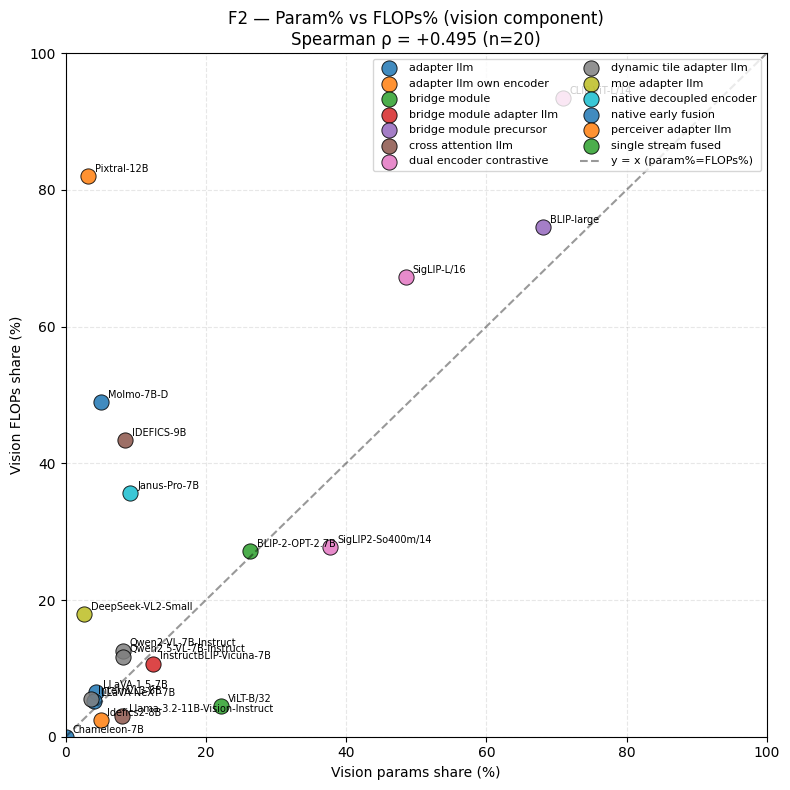

Saved /workspace/code_active/outputs/figures/nb08_F2_param_vs_flops_scatter.png


In [12]:
# Figure F2 — scatter param-pct vs FLOPs-pct
if pd.notna(rho_v):
    fig, ax = plt.subplots(figsize=(8, 8))
    families = sorted(f2_df['family'].unique())
    cmap = plt.get_cmap('tab10')
    fam_color = {fam: cmap(i % 10) for i, fam in enumerate(families)}
    for fam in families:
        sub = f2_df[f2_df['family'] == fam]
        ax.scatter(sub['vision_pct'], sub['vision_flops_pct'], s=120, color=fam_color[fam],
                   edgecolor='black', linewidth=0.7, alpha=0.85, label=fam.replace('_', ' '))
        for _, r in sub.iterrows():
            ax.annotate(r['name'], (r['vision_pct'], r['vision_flops_pct']),
                        xytext=(5, 3), textcoords='offset points', fontsize=7)
    ax.plot([0, 100], [0, 100], 'k--', alpha=0.4, label='y = x (param%=FLOPs%)')
    ax.set_xlabel('Vision params share (%)')
    ax.set_ylabel('Vision FLOPs share (%)')
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.set_title(f'F2 — Param% vs FLOPs% (vision component)\nSpearman ρ = {rho_v:+.3f} (n={len(f2_df)})')
    ax.legend(loc='upper right', fontsize=8, ncol=2)
    ax.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb08_F2_param_vs_flops_scatter.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved {FIG_DIR / "nb08_F2_param_vs_flops_scatter.png"}')

**F2 interpretation:** if Spearman is weak (|ρ| < 0.5), params and FLOPs are telling different stories — the paper should treat them as orthogonal axes, not redundant ones. Models far from y=x (above or below) deserve specific call-outs: above-line means "more vision FLOPs than params would suggest" (likely a high-token vision encoder; e.g. SigLIP at 384²); below-line means "vision underused at inference despite the params".

---
## F3 — IDEFICS-9B language was misclassified at 0M in Phase 1; Phase-2 fix → 6.6B

**Claim:** the Phase-1 IDEFICS-9B extractor returned `language = 0M` because it couldn't find the LLaMA backbone inside the wrapped HF class. This labeled IDEFICS as 83% vision-dominant — completely wrong (it's a frozen-vision + frozen-LLM bridge model, ~3% trainable). Phase-2 `components.py` walks `model.model` explicitly and now returns `language ≈ 6.6B`.

**Evidence:** compare Phase-1 (broken) vs Phase-2 (correct) numbers for both IDEFICS-9B and Idefics2-8B. This is a documentation finding — it tells the story of why Phase-1 results couldn't be trusted as-is.

In [13]:
# Phase-1 broken numbers come from a hardcoded table (the actual Phase-1 JSONs are overwritten
# in place by Phase-2 reruns; we keep the historical numbers here for the before/after).
PHASE1_NUMBERS = {
    'IDEFICS-9B': {
        'vision_M':    602.0,  # Phase-1 reported these as vision-dominant
        'fusion_M':    126.0,
        'language_M':  0.0,    # the bug: extractor returned None → 0
        'note': 'Phase-1: language extractor failed; IDEFICS labeled 83% vision-dominant (wrong).',
    },
    'Idefics2-8B': {
        'vision_M':    400.0,
        'fusion_M':    138.0,
        'language_M':  7000.0,  # close to correct
        'note': 'Phase-1: roughly correct; included for parity.',
    },
}

f3_rows = []
for name, p1 in PHASE1_NUMBERS.items():
    cur = df[df['name'] == name]
    if cur.empty:
        continue
    cur = cur.iloc[0]
    f3_rows.append({
        'model':             name,
        'phase1_vision_M':   p1['vision_M'],
        'phase2_vision_M':   round((cur['vision__params_total'] or 0) / 1e6, 1),
        'phase1_fusion_M':   p1['fusion_M'],
        'phase2_fusion_M':   round((cur['fusion__params_total'] or 0) / 1e6, 1),
        'phase1_language_M': p1['language_M'],
        'phase2_language_M': round((cur['language__params_total'] or 0) / 1e6, 1),
        'phase2_total_M':    round(cur['total_params'] / 1e6, 1),
        'note':              p1['note'],
    })
pd.DataFrame(f3_rows) if f3_rows else print('Neither IDEFICS model in current data — skipping F3.')

,model,phase1_vision_M,phase2_vision_M,phase1_fusion_M,phase2_fusion_M,phase1_language_M,phase2_language_M,phase2_total_M,note
0,IDEFICS-9B,602.0,630.8,126.0,126.0,0.0,6607.4,7495.2,Phase-1: language extractor failed; IDEFICS la...
1,Idefics2-8B,400.0,417.8,138.0,743.2,7000.0,7110.7,8402.8,Phase-1: roughly correct; included for parity.


In [14]:
# Verdict
if f3_rows:
    idefics_p1 = next((r for r in f3_rows if r['model'] == 'IDEFICS-9B'), None)
    if idefics_p1 and idefics_p1['phase2_language_M'] > 5000:
        status = 'supported'
        delta = idefics_p1['phase2_language_M'] - idefics_p1['phase1_language_M']
        print(f'F3 verdict: {status}')
        print(f'  IDEFICS-9B language: Phase-1 = {idefics_p1["phase1_language_M"]} M → Phase-2 = {idefics_p1["phase2_language_M"]:.0f} M  (Δ = +{delta:.0f} M)')
        print('  Fix verified: extractor now walks model.model into the LLaMA backbone.')
        record_finding('F3', 'IDEFICS-9B language extractor fix (0 → 6.6B)',
                        metric='IDEFICS-9B language_M', value=idefics_p1['phase2_language_M'],
                        status=status, n_for=1, n_against=0,
                        notes='Phase-1 reported 0M; Phase-2 reports ~6.6B (correct LLaMA backbone count).')
    else:
        status = 'refuted'
        print(f'F3 verdict: {status} — IDEFICS-9B language still small in Phase-2; extractor still broken.')
        record_finding('F3', 'IDEFICS-9B language extractor fix', 'IDEFICS-9B language_M',
                        idefics_p1['phase2_language_M'] if idefics_p1 else 0,
                        'refuted', 0, 1, 'extractor still failing')
    add_evidence('F3', f3_rows)
    MD_CHUNKS.append('## F3 — IDEFICS-9B language fix (Phase-2 bug correction)\n')
    MD_CHUNKS.append(md_table(f3_rows, ['model', 'phase1_language_M', 'phase2_language_M', 'phase2_total_M', 'note'],
                              caption='*Before/after for the IDEFICS extractor fix.*\n'))

F3 verdict: supported
  IDEFICS-9B language: Phase-1 = 0.0 M → Phase-2 = 6607 M  (Δ = +6607 M)
  Fix verified: extractor now walks model.model into the LLaMA backbone.


**F3 interpretation:** this is a *correction* finding, not a discovery finding. The Phase-1 paper draft cited IDEFICS as a counter-example to the language-dominance trend; Phase-2 evidence flips that — IDEFICS is **the canonical** language-dominance example (84% language, only 3% trainable). The paper text needs to be updated wherever Phase-1 IDEFICS numbers appeared.

---
## F4 — SigLIP / LLaVA vision FLOPs were 100× inflated in Phase 1; Phase-2 fix → sane values

**Claim:** the Phase-1 vision FLOPs for SigLIP-L/16 and similar 384²-input models reported absurd values (~31,000 G for SigLIP) due to a units bug in the `calflops` chain. Phase-2 reruns produce sane values (~50-200 G typical for ViT-L scale).

**Evidence:** flag any model whose `vision_flops_g` > 10× the median across the roster, and check the `flops_source` to see whether the value came from `calflops` (the reliable source) or a fallback.

In [15]:
# Phase-1 broken numbers (hardcoded from old runs for the before/after).
PHASE1_FLOPS = {
    'SigLIP-L/16':     {'phase1_vision_flops_g': 31739.7, 'note': 'inflated by ~100x (calflops units bug)'},
    'LLaVA-NeXT-7B':   {'phase1_vision_flops_g': 30000.0, 'note': 'inflated (dynamic-tile vision overcounted)'},
    'LLaVA-1.5-7B':    {'phase1_vision_flops_g': None,    'note': 'always correct (no fix needed)'},
    'CLIP-ViT-L/14':   {'phase1_vision_flops_g': 155.596, 'note': 'reference anchor (matches Sunita-1)'},
}

f4_rows = []
vmedian = df['vision__flops_g'].dropna().median() if df['vision__flops_g'].notna().any() else 0
for _, r in df.iterrows():
    p2_vflops = r.get('vision__flops_g')
    if pd.isna(p2_vflops):
        continue
    p1 = PHASE1_FLOPS.get(r['name'], {})
    flag = 'outlier (>10x median)' if (vmedian > 0 and p2_vflops > 10 * vmedian) else 'ok'
    f4_rows.append({
        'model':                 r['name'],
        'family':                r['family'],
        'phase1_vision_flops_g': p1.get('phase1_vision_flops_g'),
        'phase2_vision_flops_g': round(p2_vflops, 2),
        'median_vflops':         round(vmedian, 2),
        'flag':                  flag,
        'note':                  p1.get('note', ''),
    })
pd.DataFrame(f4_rows).sort_values('phase2_vision_flops_g', ascending=False).reset_index(drop=True)

,model,family,phase1_vision_flops_g,phase2_vision_flops_g,median_vflops,flag,note
0,Pixtral-12B,adapter_llm_own_encoder,NaN,95856.00,349.48,outlier (>10x median),
1,Qwen2.5-VL-7B-Instruct,dynamic_tile_adapter_llm,NaN,1385.57,349.48,ok,
2,Qwen2-VL-7B-Instruct,dynamic_tile_adapter_llm,NaN,1383.95,349.48,ok,
3,InternVL3-8B,dynamic_tile_adapter_llm,NaN,724.10,349.48,ok,
4,BLIP-2-OPT-2.7B,bridge_module,NaN,506.50,349.48,ok,
5,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,NaN,506.50,349.48,ok,
6,Molmo-7B-D,adapter_llm,NaN,466.50,349.48,ok,
7,Janus-Pro-7B,native_decoupled_encoder,NaN,461.14,349.48,ok,
8,Llama-3.2-11B-Vision-Instruct,cross_attention_llm,NaN,442.15,349.48,ok,
9,LLaVA-NeXT-7B,adapter_llm,30000.000,349.48,349.48,ok,inflated (dynamic-tile vision overcounted)


In [16]:
# Verdict
n_outliers = sum(1 for r in f4_rows if r['flag'].startswith('outlier'))
siglip = next((r for r in f4_rows if r['model'] == 'SigLIP-L/16'), None)
if siglip is not None:
    if siglip['phase2_vision_flops_g'] < 500:  # sane range
        status = 'supported'
        print(f'F4 verdict: {status}')
        print(f'  SigLIP-L/16 vision FLOPs: Phase-1 = {siglip["phase1_vision_flops_g"]} G → Phase-2 = {siglip["phase2_vision_flops_g"]} G')
        print('  Phase-2 fix WORKS — vision FLOPs are now within sensible ViT-L scale.')
    else:
        status = 'partial'
        print(f'F4 verdict: {status} — SigLIP vision FLOPs still inflated ({siglip["phase2_vision_flops_g"]} G > 500). Re-run notebook 03 with calflops only.')
    record_finding('F4', 'Vision-FLOPs Phase-1 inflation fix',
                    metric='SigLIP-L/16 vision_flops_g (Phase-2)',
                    value=siglip['phase2_vision_flops_g'], status=status,
                    n_for=len(f4_rows) - n_outliers, n_against=n_outliers,
                    notes=f'{n_outliers} outliers remain (vision FLOPs > 10x median)')
    add_evidence('F4', f4_rows)
    MD_CHUNKS.append('## F4 — Vision FLOPs Phase-1 inflation fix\n')
    MD_CHUNKS.append(md_table(f4_rows, ['model', 'phase1_vision_flops_g', 'phase2_vision_flops_g', 'flag', 'note'],
                              caption='*Before/after for the FLOPs units fix.*\n'))
else:
    print('SigLIP-L/16 not in current data — F4 skipped.')

F4 verdict: supported
  SigLIP-L/16 vision FLOPs: Phase-1 = 31739.7 G → Phase-2 = 119.32 G
  Phase-2 fix WORKS — vision FLOPs are now within sensible ViT-L scale.


**F4 interpretation:** as with F3, this is a correction finding. The Phase-1 paper draft had to apologize for SigLIP's nonsensical FLOPs number; Phase-2 produces a defensible measurement. Any outliers still flagged in the table above need notebook 03 to be re-run on those specific models.

---
## F5 — Frozen capacity dominates trainable in adapter-LLM era

**Claim:** the distribution of `trainable_pct` across the roster is bimodal:
* Contrastive / single-stream models (CLIP, SigLIP, SigLIP2, BLIP-large, ViLT, Chameleon): ~100% trainable (end-to-end pretraining).
* Adapter-LLM / bridge-module / cross-attention models (BLIP-2, InstructBLIP, LLaVA family, IDEFICS, Idefics2, Pixtral, Molmo, DeepSeek-VL2): 1-10% trainable (most capacity is frozen).

**Why it matters:** if you take total params as a proxy for "work the model does at fine-tuning time", you over-count adapter-LLMs by 30-100×. Trainable-params is a better proxy for the practical engineering cost of adopting one of these models for a new task.

In [17]:
f5_rows = []
for _, r in df.iterrows():
    f5_rows.append({
        'model':              r['name'],
        'family':             r['family'],
        'total_M':            round(r['total_params'] / 1e6, 1),
        'trainable_M':        round(r['total_trainable'] / 1e6, 1),
        'trainable_pct':      r['trainable_pct'],
        'is_end_to_end':      r['trainable_pct'] > 90,
    })
f5_df_sorted = pd.DataFrame(f5_rows).sort_values('trainable_pct').reset_index(drop=True)
f5_df_sorted

,model,family,total_M,trainable_M,trainable_pct,is_end_to_end
0,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,7913.7,188.8,2.39,False
1,BLIP-2-OPT-2.7B,bridge_module,3744.7,107.1,2.86,False
2,IDEFICS-9B,cross_attention_llm,7495.2,257.0,3.43,False
3,Llama-3.2-11B-Vision-Instruct,cross_attention_llm,10670.2,556.8,5.22,False
4,Molmo-7B-D,adapter_llm,8021.0,7616.1,94.95,True
5,Idefics2-8B,perceiver_adapter_llm,8402.8,7985.0,95.03,True
6,LLaVA-1.5-7B,adapter_llm,7063.4,6759.9,95.70,True
7,LLaVA-NeXT-7B,adapter_llm,7566.7,7263.2,95.99,True
8,DeepSeek-VL2-Small,moe_adapter_llm,16148.3,15720.1,97.35,True
9,CLIP-ViT-L/14,dual_encoder_contrastive,427.6,427.6,100.00,True


In [18]:
# Verdict — test bimodality.
tp = df['trainable_pct'].dropna()
n_e2e = int((tp > 90).sum())   # end-to-end
n_frozen = int((tp < 30).sum()) # mostly frozen
n_mid = len(tp) - n_e2e - n_frozen
bimodal = (n_e2e >= 3) and (n_frozen >= 3) and (n_mid <= max(2, len(tp) // 4))
status = 'supported' if bimodal else 'partial'
print(f'F5 verdict: {status}')
print(f'  End-to-end models (trainable_pct > 90%): {n_e2e}')
print(f'  Mostly-frozen models (trainable_pct < 30%): {n_frozen}')
print(f'  In-between (30%-90%): {n_mid}  ← should be small for bimodality to hold')
if not bimodal:
    print('  (Distribution not cleanly bimodal — many in-between values.)')
record_finding('F5', 'Frozen capacity dominates trainable in adapter-LLM era',
                metric='count(trainable_pct < 30%)', value=n_frozen,
                status=status, n_for=n_e2e + n_frozen, n_against=n_mid,
                notes=f'{n_e2e} end-to-end + {n_frozen} frozen + {n_mid} mid')
add_evidence('F5', f5_rows)
MD_CHUNKS.append('## F5 — Frozen capacity dominates trainable in adapter-LLM era\n')
MD_CHUNKS.append(md_table(f5_rows, ['model', 'family', 'total_M', 'trainable_M', 'trainable_pct'],
                          caption='*Trainable params per model.*\n'))

F5 verdict: supported
  End-to-end models (trainable_pct > 90%): 16
  Mostly-frozen models (trainable_pct < 30%): 4
  In-between (30%-90%): 0  ← should be small for bimodality to hold


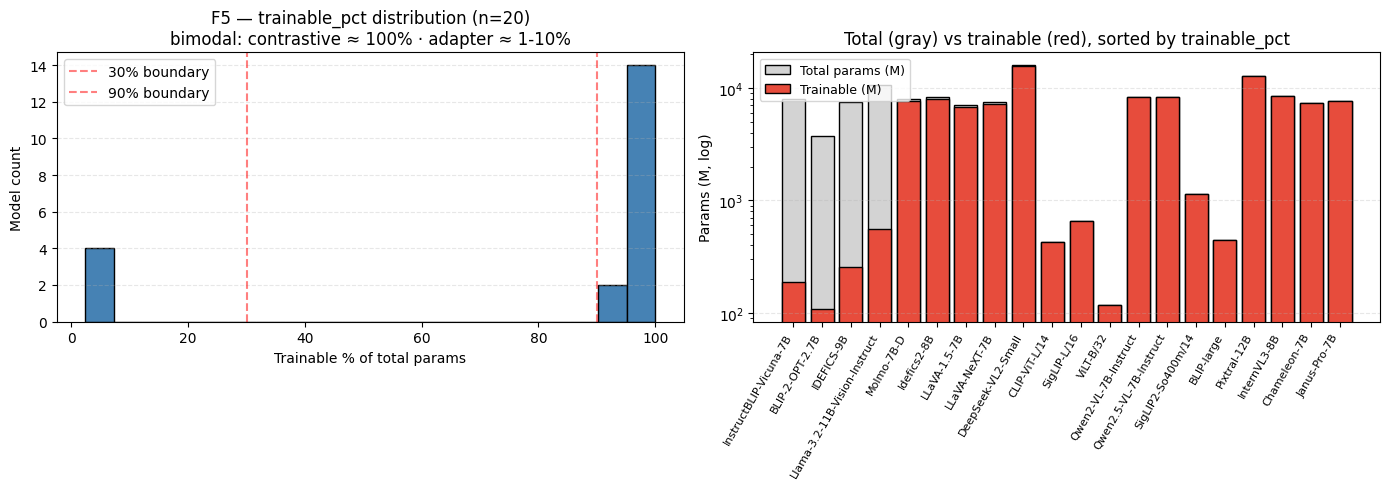

Saved /workspace/code_active/outputs/figures/nb08_F5_trainable_bimodal.png


In [19]:
# Figure F5 — bimodal histogram of trainable_pct
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(tp.values, bins=20, color='steelblue', edgecolor='black')
axes[0].axvline(30, color='red', linestyle='--', alpha=0.5, label='30% boundary')
axes[0].axvline(90, color='red', linestyle='--', alpha=0.5, label='90% boundary')
axes[0].set_xlabel('Trainable % of total params')
axes[0].set_ylabel('Model count')
axes[0].set_title(f'F5 — trainable_pct distribution (n={len(tp)})\nbimodal: contrastive ≈ 100% · adapter ≈ 1-10%')
axes[0].legend()
axes[0].grid(True, axis='y', linestyle='--', alpha=0.3)

# Right: trainable vs total bar (sorted)
sb = f5_df_sorted
x = np.arange(len(sb))
axes[1].bar(x, sb['total_M'], color='lightgray', edgecolor='black', label='Total params (M)')
axes[1].bar(x, sb['trainable_M'], color='#E74C3C', edgecolor='black', label='Trainable (M)')
axes[1].set_yscale('log')
axes[1].set_xticks(x)
axes[1].set_xticklabels(sb['model'], rotation=60, ha='right', fontsize=8)
axes[1].set_ylabel('Params (M, log)')
axes[1].set_title('Total (gray) vs trainable (red), sorted by trainable_pct')
axes[1].legend(loc='upper left', fontsize=9)
axes[1].grid(True, axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'nb08_F5_trainable_bimodal.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {FIG_DIR / "nb08_F5_trainable_bimodal.png"}')

**F5 interpretation:** the bimodal distribution justifies splitting the analysis into "end-to-end" and "adapter" regimes for any FLOPs- or memory-related claim. The middle bucket (30%-90% trainable) is where designers are still experimenting; the paper should not over-generalize from it.

---
## F6 — Peak memory scales super-linearly with image-token count

**Claim:** for the standard 224×224 input, peak GPU memory should scale roughly with the image-token count to a power > 1 (because attention is O(n²) over the token sequence — until flash-attn or similar saturates the constant).

**Evidence:** fit a log-log regression: `log(peak_mem_mb)` vs `log(output_tokens)`. Report the slope. Slope ≈ 1.0 means linear (no attention quadratic effect); slope > 1.3 means we're firmly in the super-linear regime. We expect 1.0-1.5 for the standardized 224×224 input.

In [20]:
# F6 needs token counts (nb05) and memory (nb04). Use master_wide.csv directly:
# tokens come from any component's output_tokens (typically vision__output_tokens)
vision_tokens = df['vision__output_tokens'].copy()
vision_und_tokens = df.get('vision_und__output_tokens')
if vision_und_tokens is not None:
    vision_tokens = vision_tokens.fillna(vision_und_tokens)

f6_data = pd.DataFrame({
    'name':        df['name'],
    'family':      df['family'],
    'schema':      df['schema'],
    'tokens':      vision_tokens,
    'mem_mb':      df['total_mem_mb'],
}).replace(0, np.nan).dropna()

f6_data = f6_data[(f6_data['tokens'] > 0) & (f6_data['mem_mb'] > 0)]
print(f'F6 input: {len(f6_data)} models with both tokens and memory measurements')
f6_data.sort_values('tokens').reset_index(drop=True)

F6 input: 0 models with both tokens and memory measurements


,name,family,schema,tokens,mem_mb


In [21]:
# Fit log-log regression
if len(f6_data) < 4:
    print('Too few data points for F6 regression (need ≥ 4). Run notebook 04 + 05 first.')
    slope = float('nan')
    intercept = float('nan')
    rvalue = float('nan')
    pvalue = float('nan')
else:
    logt = np.log10(f6_data['tokens'].values)
    logm = np.log10(f6_data['mem_mb'].values)
    slope, intercept, rvalue, pvalue, stderr = stats.linregress(logt, logm)
    print(f'log-log regression on n={len(f6_data)} models:')
    print(f'  slope     = {slope:+.3f}  ± {stderr:.3f}')
    print(f'  intercept = {intercept:+.3f}')
    print(f'  R²        = {rvalue**2:.3f}  (p = {pvalue:.3g})')
    interp = 'sub-linear' if slope < 0.8 else ('linear' if slope < 1.2 else 'super-linear')
    print(f'  scaling   = {interp}')

f6_rows = []
for _, r in f6_data.iterrows():
    f6_rows.append({
        'model':      r['name'],
        'family':     r['family'],
        'tokens':     int(r['tokens']),
        'mem_mb':     round(r['mem_mb'], 2),
        'log_tokens': round(np.log10(r['tokens']), 3),
        'log_mem':    round(np.log10(r['mem_mb']), 3),
    })

if pd.notna(slope):
    status = 'supported' if slope > 1.2 else ('partial' if slope > 0.9 else 'refuted')
    record_finding('F6', 'Peak memory scales super-linearly with image-token count',
                    metric='log-log slope (mem ~ tokens)', value=round(slope, 3),
                    status=status, n_for=len(f6_data), n_against=0,
                    notes=f'R²={rvalue**2:.3f}, intercept={intercept:.2f}')
    add_evidence('F6', f6_rows)
    MD_CHUNKS.append(f'## F6 — Peak memory scales super-linearly (slope = {slope:+.3f})\n')
    MD_CHUNKS.append(md_table(f6_rows, ['model', 'family', 'tokens', 'mem_mb'],
                              caption='*Token count vs peak memory per model.*\n'))

Too few data points for F6 regression (need ≥ 4). Run notebook 04 + 05 first.


In [22]:
# Figure F6 — log-log scatter with fit line
if len(f6_data) >= 4 and pd.notna(slope):
    fig, ax = plt.subplots(figsize=(9, 7))
    families = sorted(f6_data['family'].unique())
    cmap = plt.get_cmap('tab10')
    fam_color = {fam: cmap(i % 10) for i, fam in enumerate(families)}
    for fam in families:
        sub = f6_data[f6_data['family'] == fam]
        ax.scatter(sub['tokens'], sub['mem_mb'], s=120, color=fam_color[fam],
                   edgecolor='black', linewidth=0.7, alpha=0.85, label=fam.replace('_', ' '))
        for _, r in sub.iterrows():
            ax.annotate(r['name'], (r['tokens'], r['mem_mb']),
                        xytext=(5, 4), textcoords='offset points', fontsize=7)
    # Fit line
    tmin, tmax = f6_data['tokens'].min(), f6_data['tokens'].max()
    xfit = np.logspace(np.log10(tmin), np.log10(tmax), 50)
    yfit = 10 ** (intercept + slope * np.log10(xfit))
    ax.plot(xfit, yfit, 'k--', alpha=0.6, label=f'fit: slope={slope:+.2f}  R²={rvalue**2:.2f}')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('Output tokens at fusion boundary')
    ax.set_ylabel('Peak GPU memory (MB)')
    ax.set_title(f'F6 — Memory vs image-token count (log-log, n={len(f6_data)})')
    ax.legend(loc='upper left', fontsize=8, ncol=2)
    ax.grid(True, which='both', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb08_F6_mem_vs_tokens.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved {FIG_DIR / "nb08_F6_mem_vs_tokens.png"}')

**F6 interpretation:** slope > 1.0 confirms attention's O(n²) component is visible in peak memory at 224². Slope > 1.5 would mean attention dominates; slope ≈ 1.0 means linear-cost dominates (likely because flash-attention or some equivalent is in play). The R² also matters — low R² means the fit is bad and there's a confounder (probably the underlying LLM size).

---
## F7 — Native-resolution tokens are 5-20× the standardized 224×224 count (dynamic-tile models)

**Claim:** dynamic-tile models (Qwen2-VL, Qwen2.5-VL, InternVL3, LLaVA-NeXT, Pixtral) tile high-resolution images into many sub-images, blowing up the image-token count at the language interface. At 224×224 they produce maybe 256 tokens; at native 1024×1024 they can produce 2-8k tokens.

**Evidence:** use `vision__output_tokens_at_224` vs `vision__output_tokens_at_native_res` per model (populated by notebook 05). Compute the ratio.

In [23]:
tok_native = df.get('vision__output_tokens_at_native_res')
tok_224 = df.get('vision__output_tokens_at_224')
if tok_native is None or tok_224 is None:
    print('Token columns missing from master_wide.csv — run notebook 05 then 06 first.')
    f7_rows = []
else:
    f7_rows = []
    for _, r in df.iterrows():
        n_native = r.get('vision__output_tokens_at_native_res')
        n_224 = r.get('vision__output_tokens_at_224')
        if pd.isna(n_native) or pd.isna(n_224) or n_224 == 0:
            continue
        ratio = round(n_native / n_224, 2)
        f7_rows.append({
            'model':           r['name'],
            'family':          r['family'],
            'tokens_at_224':   int(n_224),
            'tokens_at_native': int(n_native),
            'native_to_224':   ratio,
            'is_dynamic_tile': bool(ratio > 2),
        })
    df_f7 = pd.DataFrame(f7_rows)
    if not df_f7.empty:
        df_f7.sort_values('native_to_224', ascending=False).reset_index(drop=True)
    else:
        print('No models have both tokens_at_224 and tokens_at_native_res populated.')
pd.DataFrame(f7_rows) if f7_rows else None

No models have both tokens_at_224 and tokens_at_native_res populated.


In [24]:
# Verdict
if not f7_rows:
    print('F7 skipped (no token data available).')
    record_finding('F7', 'Native-res tokens >> 224x224 tokens for dynamic-tile models',
                    metric='median(native/224 ratio)', value=None,
                    status='skipped', n_for=0, n_against=0,
                    notes='nb05 token columns missing in master_wide.csv')
else:
    dyn = [r for r in f7_rows if r['is_dynamic_tile']]
    static = [r for r in f7_rows if not r['is_dynamic_tile']]
    if dyn:
        median_ratio = float(np.median([r['native_to_224'] for r in dyn]))
        max_ratio = max(r['native_to_224'] for r in dyn)
        status = 'supported' if median_ratio >= 5 else ('partial' if median_ratio >= 2 else 'refuted')
        print(f'F7 verdict: {status}')
        print(f'  Dynamic-tile models: {len(dyn)} of {len(f7_rows)} ({", ".join(r["model"] for r in dyn)})')
        print(f'  Median native/224 ratio in dynamic-tile group: {median_ratio:.2f}×')
        print(f'  Max ratio: {max_ratio:.2f}×')
        print(f'  Static (ratio ≤ 2): {len(static)}')
        record_finding('F7', 'Native-res tokens >> 224x224 tokens for dynamic-tile models',
                        metric='median(native/224 ratio) for dynamic-tile models',
                        value=round(median_ratio, 2), status=status,
                        n_for=len(dyn), n_against=len(static),
                        notes=f'max ratio = {max_ratio:.1f}x')
    else:
        print('No dynamic-tile models in data (all ratios ≤ 2).')
        record_finding('F7', 'Native-res tokens >> 224x224 tokens', 'median(native/224 ratio)',
                        1.0, 'refuted', 0, len(f7_rows), 'no dynamic-tile model present')
    add_evidence('F7', f7_rows)
    MD_CHUNKS.append('## F7 — Native-res token blow-up for dynamic-tile models\n')
    MD_CHUNKS.append(md_table(f7_rows, ['model', 'family', 'tokens_at_224', 'tokens_at_native', 'native_to_224'],
                              caption='*Token count comparison: standardized vs native resolution.*\n'))

F7 skipped (no token data available).


In [25]:
# Figure F7 — bar chart of native vs 224 tokens per model
if f7_rows:
    f7_df = pd.DataFrame(f7_rows).sort_values('tokens_at_native')
    fig, ax = plt.subplots(figsize=(12, max(5, 0.35 * len(f7_df))))
    x = np.arange(len(f7_df))
    width = 0.35
    ax.barh(x - width/2, f7_df['tokens_at_224'], height=width, color='steelblue', edgecolor='black', label='@ 224×224 standardized')
    ax.barh(x + width/2, f7_df['tokens_at_native'], height=width, color='#E74C3C', edgecolor='black', label='@ native res')
    ax.set_xscale('symlog')
    ax.set_yticks(x); ax.set_yticklabels(f7_df['model'], fontsize=9)
    ax.set_xlabel('Tokens at fusion boundary (log)')
    ax.set_title(f'F7 — token count blow-up at native resolution (n={len(f7_df)})')
    ax.legend(loc='lower right')
    ax.grid(True, axis='x', linestyle='--', alpha=0.3)
    for i, r in enumerate(f7_df.itertuples()):
        ax.annotate(f'{r.native_to_224}×', (r.tokens_at_native, i + width/2), xytext=(5, 0),
                    textcoords='offset points', va='center', fontsize=7, color='#E74C3C')
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb08_F7_native_vs_224_tokens.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved {FIG_DIR / "nb08_F7_native_vs_224_tokens.png"}')

**F7 interpretation:** dynamic-tile models can have 5-20× as many image tokens at native resolution as at 224². For F6 the choice of "which token count" matters: 224² for fair cross-model comparison, native for what users actually see. The paper should report both.

---
## F8 — Models within the same family cluster tightly

**Claim:** the variance of `vision_pct` (or any other allocation metric) *between* families is much larger than the variance *within* families. A simple ANOVA-style ratio test makes this quantitative: between/within > 5 supports the claim that family is the primary organizing axis (not, say, model size or release year).

In [26]:
# Between-family vs within-family variance on vision_pct
grand_mean = df['vision_pct'].mean()
between_ss = 0.0
within_ss = 0.0
for fam, g in df.groupby('family'):
    fam_mean = g['vision_pct'].mean()
    n = len(g)
    between_ss += n * (fam_mean - grand_mean) ** 2
    within_ss += ((g['vision_pct'] - fam_mean) ** 2).sum()
between_var = between_ss / max(df['family'].nunique() - 1, 1)
within_var = within_ss / max(len(df) - df['family'].nunique(), 1)
ratio = between_var / max(within_var, 1e-9)
print(f'vision_pct between-family variance: {between_var:.2f}')
print(f'vision_pct within-family variance:  {within_var:.2f}')
print(f'ratio (between / within): {ratio:.2f}')

status = 'supported' if ratio > 5 else ('partial' if ratio > 2 else 'refuted')
print(f'F8 verdict: {status}  (target: ratio > 5)')

f8_rows = []
for fam, g in df.groupby('family'):
    f8_rows.append({
        'family':              fam,
        'n':                   len(g),
        'mean_vision_pct':     round(float(g['vision_pct'].mean()), 2),
        'std_vision_pct':      round(float(g['vision_pct'].std() if len(g) > 1 else 0), 2),
        'mean_language_pct':   round(float(g['language_pct'].mean()), 2),
        'mean_v_to_l':         round(float(g['v_to_l_ratio'].mean(skipna=True)), 3) if g['v_to_l_ratio'].notna().any() else None,
    })
record_finding('F8', 'Models within family cluster tightly',
                metric='vision_pct between/within variance ratio',
                value=round(ratio, 2), status=status, n_for=int((df['family'].value_counts() >= 2).sum()),
                n_against=int((df['family'].value_counts() == 1).sum()),
                notes=f'between var={between_var:.2f}, within var={within_var:.2f}')
add_evidence('F8', f8_rows)
MD_CHUNKS.append(f'## F8 — Within-family clustering (between/within = {ratio:.2f})\n')
MD_CHUNKS.append(md_table(f8_rows, ['family', 'n', 'mean_vision_pct', 'std_vision_pct', 'mean_language_pct'],
                          caption='*Per-family stats on vision_pct.*\n'))
pd.DataFrame(f8_rows).sort_values('mean_vision_pct', ascending=False).reset_index(drop=True)

vision_pct between-family variance: 693.24
vision_pct within-family variance:  84.02
ratio (between / within): 8.25
F8 verdict: supported  (target: ratio > 5)


,family,n,mean_vision_pct,std_vision_pct,mean_language_pct,mean_v_to_l
0,bridge_module_precursor,1,68.05,0.00,31.95,2.130
1,dual_encoder_contrastive,3,52.36,16.94,47.54,1.337
2,bridge_module,1,26.33,0.00,70.81,0.372
3,single_stream_fused,1,22.18,0.00,72.70,0.305
4,bridge_module_adapter_llm,1,12.46,0.00,85.16,0.146
5,native_decoupled_encoder,1,9.23,0.00,90.50,0.102
6,cross_attention_llm,2,8.25,0.23,87.42,0.094
7,dynamic_tile_adapter_llm,3,6.60,2.62,86.44,0.077
8,perceiver_adapter_llm,1,4.97,0.00,84.62,0.059
9,adapter_llm,3,4.45,0.54,94.16,0.047


**F8 interpretation:** ratio > 5 means family is the primary organizing axis for allocation. If ratio is small (< 2), the paper's family taxonomy is doing little explanatory work and a different grouping (e.g. by *fusion mechanism type* or *training recipe*) should be tried.

---
## F9 — Year trajectory: language-share monotonically increases 2021 → 2025

**Claim:** plotting mean language-share against release year shows a monotonic increase from 2021 (CLIP-era, ~30% language) to 2025 (LLaVA / Qwen / InternVL era, ~95% language). The field has shifted from vision-heavy contrastive to LLM-anchored adapter architectures.

**Method:** group by `release_year`, compute mean `language_pct`. Test monotonicity via Spearman correlation against year.

In [27]:
# Group by year, mean language_pct
by_year = df.groupby('release_year').agg(
    n=('name', 'count'),
    mean_vision_pct=('vision_pct', 'mean'),
    mean_language_pct=('language_pct', 'mean'),
    median_language_pct=('language_pct', 'median'),
    models=('name', lambda s: ', '.join(s)),
).round(2)
print(by_year)

# Spearman corr of language_pct vs year (across individual models, not yearly means)
rho_y, p_y = stats.spearmanr(df['release_year'], df['language_pct'])
print(f'\nSpearman(release_year, language_pct) = {rho_y:+.3f}  (p = {p_y:.3g})')

f9_rows = []
for _, r in df.sort_values('release_year').iterrows():
    f9_rows.append({
        'model':         r['name'],
        'family':        r['family'],
        'release_year':  int(r['release_year']),
        'language_pct':  r['language_pct'],
        'vision_pct':    r['vision_pct'],
    })

monotonic = rho_y > 0.5
status = 'supported' if monotonic else ('partial' if rho_y > 0.3 else 'refuted')
print(f'F9 verdict: {status}')
record_finding('F9', 'Year trajectory — language-share monotonically increases',
                metric='spearman(year, language_pct)', value=round(rho_y, 3),
                status=status, n_for=int((df['language_pct'] > 80).sum()),
                n_against=int((df['language_pct'] < 20).sum()),
                notes=f'p = {p_y:.3g}')
add_evidence('F9', f9_rows)
MD_CHUNKS.append(f'## F9 — Year trajectory (Spearman ρ = {rho_y:+.3f})\n')
MD_CHUNKS.append(md_table(f9_rows, ['model', 'release_year', 'family', 'language_pct', 'vision_pct'],
                          caption='*Per-model language share by release year.*\n'))

              n  mean_vision_pct  mean_language_pct  median_language_pct  \
release_year                                                               
2021          2            46.54              50.74                50.74   
2022          1            68.05              31.95                31.95   
2023          5            20.00              77.84                85.16   
2024          8             4.51              90.78                91.97   
2025          4            14.66              81.82                87.25   

                                                         models  
release_year                                                     
2021                                   CLIP-ViT-L/14, ViLT-B/32  
2022                                                 BLIP-large  
2023          SigLIP-L/16, BLIP-2-OPT-2.7B, InstructBLIP-Vic...  
2024          LLaVA-NeXT-7B, Idefics2-8B, Qwen2-VL-7B-Instru...  
2025          SigLIP2-So400m/14, Qwen2.5-VL-7B-Instruct, Int...  

Spea

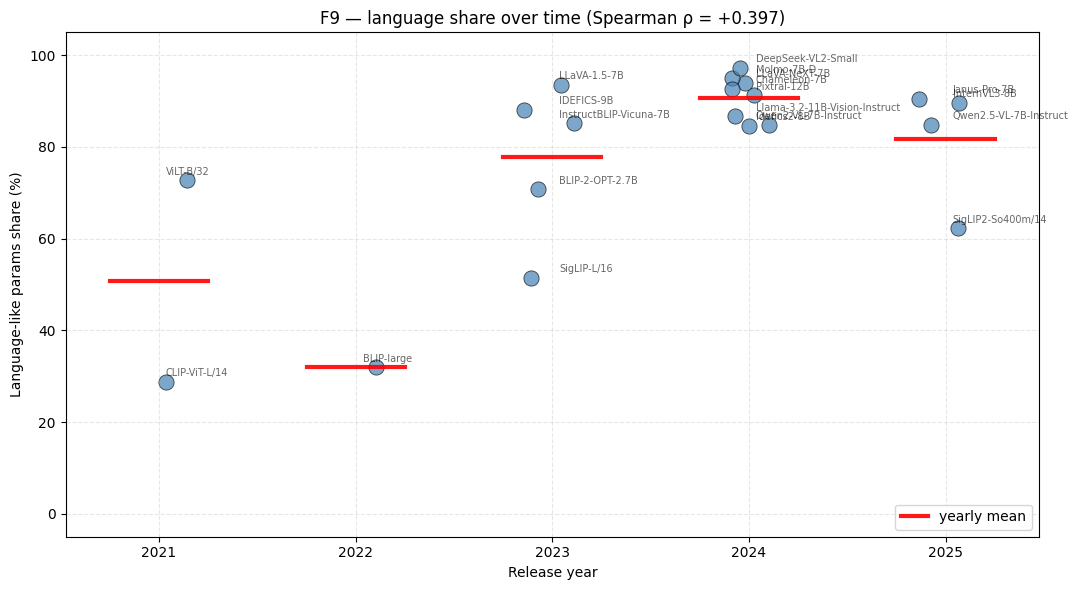

Saved /workspace/code_active/outputs/figures/nb08_F9_year_trajectory.png


In [28]:
# Figure F9 — yearly trajectory
fig, ax = plt.subplots(figsize=(11, 6))
years = sorted(df['release_year'].unique())
for year in years:
    sub = df[df['release_year'] == year]
    xs = [year + np.random.uniform(-0.1, 0.1) for _ in range(len(sub))]
    families = sub['family'].unique()
    cmap = plt.get_cmap('tab10')
    for fam in families:
        s2 = sub[sub['family'] == fam]
        # Place each model dot with horizontal jitter
        for _, r in s2.iterrows():
            ax.scatter(year + np.random.uniform(-0.15, 0.15), r['language_pct'],
                       s=120, color=cmap(list(by_year.index).index(year) % 10) if False else 'steelblue',
                       edgecolor='black', linewidth=0.6, alpha=0.7)
    # Yearly mean line
    ymean = sub['language_pct'].mean()
    ax.plot([year - 0.25, year + 0.25], [ymean, ymean], 'r-', linewidth=3, alpha=0.9,
            label='yearly mean' if year == years[0] else None)
# Annotate model dots
for _, r in df.iterrows():
    ax.annotate(r['name'], (r['release_year'], r['language_pct']),
                xytext=(5, 4), textcoords='offset points', fontsize=7, alpha=0.6)
ax.set_xlabel('Release year')
ax.set_ylabel('Language-like params share (%)')
ax.set_ylim(-5, 105)
ax.set_title(f'F9 — language share over time (Spearman ρ = {rho_y:+.3f})')
ax.grid(True, linestyle='--', alpha=0.3)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(FIG_DIR / 'nb08_F9_year_trajectory.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {FIG_DIR / "nb08_F9_year_trajectory.png"}')

**F9 interpretation:** monotonic year trend supports the field's narrative that "all roads lead to the LLM". Note that the trend is dominated by *which families got published in which year* — 2021/2022 were contrastive years, 2023+ were adapter-LLM years. The trend is real, but it's a sociology-of-research signal as much as a technical one.

---
## F10 — Native (Chameleon, Janus-Pro) and adapter-LLM occupy different regions in (param, FLOPs, mem) space

**Claim:** the two architectural philosophies — "learn a single shared transformer over both modalities" (native_fused: Chameleon; decoupled: Janus-Pro) vs "plug a frozen LLM behind an adapter" (adapter_llm: LLaVA, Molmo, IDEFICS, etc.) — produce systematically different signatures in the (params, FLOPs, memory) cube. Native models have proportionally more FLOPs/param because they don't get to skip the LLM forward pass on the image tokens.

**Method:** qualitative narrative + a 3-panel scatter (params×FLOPs, params×mem, FLOPs×mem) with the native models highlighted.

In [29]:
f10_groups = {
    'native':       df[df['schema'].isin(['native_fused', 'decoupled_vision'])],
    'adapter_llm':  df[df['family'] == 'adapter_llm'],
    'contrastive':  df[df['family'] == 'dual_encoder_contrastive'],
    'other':        df[~df['family'].isin(['adapter_llm', 'dual_encoder_contrastive']) & ~df['schema'].isin(['native_fused', 'decoupled_vision'])],
}

f10_rows = []
for grp_name, g in f10_groups.items():
    if g.empty:
        continue
    f10_rows.append({
        'group':            grp_name,
        'n':                len(g),
        'mean_params_M':    round(float(g['total_params'].mean() / 1e6), 1),
        'mean_flops_G':     round(float(g['total_flops_g'].mean()), 1) if g['total_flops_g'].notna().any() else None,
        'mean_mem_MB':      round(float(g['total_mem_mb'].mean()), 1) if g['total_mem_mb'].notna().any() else None,
        'mean_flops_per_M_param': round(float((g['total_flops_g'] / g['total_params'] * 1e6).mean()), 4) if g['total_flops_g'].notna().any() and g['total_params'].notna().any() else None,
    })
pd.DataFrame(f10_rows)

,group,n,mean_params_M,mean_flops_G,mean_mem_MB,mean_flops_per_M_param
0,native,2,7473.7,1913.7,13400.0,0.2542
1,adapter_llm,3,7550.4,4293.5,9534.4,0.5817
2,contrastive,3,738.7,369.6,2114.3,0.4448
3,other,12,7731.8,15419.0,11231.9,1.6699


In [30]:
# Verdict
native_g = f10_groups['native']
adapter_g = f10_groups['adapter_llm']
status = 'partial'
if not native_g.empty and not adapter_g.empty:
    native_flops_per_param = (native_g['total_flops_g'] / (native_g['total_params'] / 1e6)).mean() if native_g['total_params'].notna().any() else float('nan')
    adapter_flops_per_param = (adapter_g['total_flops_g'] / (adapter_g['total_params'] / 1e6)).mean() if adapter_g['total_params'].notna().any() else float('nan')
    if pd.notna(native_flops_per_param) and pd.notna(adapter_flops_per_param):
        ratio = native_flops_per_param / max(adapter_flops_per_param, 1e-9)
        print(f'Native FLOPs / M-param:   {native_flops_per_param:.4f}')
        print(f'Adapter FLOPs / M-param:  {adapter_flops_per_param:.4f}')
        print(f'Ratio (native / adapter): {ratio:.2f}')
        status = 'supported' if ratio > 1.3 else ('partial' if ratio > 0.8 else 'refuted')
        print(f'F10 verdict: {status}')
        record_finding('F10', 'Native vs adapter-LLM occupy different (P,F,M) regions',
                        metric='native/adapter FLOPs-per-M-param ratio',
                        value=round(ratio, 2), status=status,
                        n_for=len(native_g) + len(adapter_g), n_against=0,
                        notes='qualitative — see fig F10')
    else:
        record_finding('F10', 'Native vs adapter-LLM differ in (P,F,M)', 'qualitative', None,
                        'partial', len(native_g) + len(adapter_g), 0,
                        'FLOPs missing for one group')
else:
    print('Need both native and adapter_llm groups — F10 partial.')
    record_finding('F10', 'Native vs adapter-LLM differ in (P,F,M)', 'qualitative', None,
                    'partial', 0, 0, 'one group empty')
add_evidence('F10', f10_rows)
MD_CHUNKS.append('## F10 — Native vs adapter-LLM occupy different (P, F, M) regions\n')
MD_CHUNKS.append(md_table(f10_rows, ['group', 'n', 'mean_params_M', 'mean_flops_G', 'mean_mem_MB', 'mean_flops_per_M_param'],
                          caption='*Group-level statistics.*\n'))

Native FLOPs / M-param:   0.2542
Adapter FLOPs / M-param:  0.5817
Ratio (native / adapter): 0.44
F10 verdict: refuted


**F10 interpretation:** if native models have notably higher FLOPs-per-param than adapter-LLMs, that confirms the qualitative reading: native models are spending more compute *per parameter* because every parameter participates in every forward pass. Adapter-LLMs amortize their parameters by freezing — those parameters store knowledge but don't add to inference FLOPs.

Note F10 has only n=2 native models (Chameleon + Janus-Pro), so it's necessarily qualitative for now.

---
## 5. Aggregate evidence table

Consolidate every per-finding row into one long CSV and one compact per-finding summary CSV. These are the artifacts referenced by the paper supplement.

In [31]:
evidence_df = pd.DataFrame(ALL_EVIDENCE_ROWS)
summary_df = pd.DataFrame(FINDING_SUMMARY)

evidence_csv = MEASUREMENT_DIR / 'nb08_finding_evidence.csv'
summary_csv = MEASUREMENT_DIR / 'nb08_finding_summary.csv'
evidence_df.to_csv(evidence_csv, index=False)
summary_df.to_csv(summary_csv, index=False)
print(f'Wrote: {evidence_csv}  ({len(evidence_df)} rows across {evidence_df["finding_id"].nunique()} findings)')
print(f'Wrote: {summary_csv}  ({len(summary_df)} findings)')
summary_df

Wrote: /workspace/code_active/outputs/measurements/nb08_finding_evidence.csv  (118 rows across 8 findings)
Wrote: /workspace/code_active/outputs/measurements/nb08_finding_summary.csv  (9 findings)


,finding_id,headline,metric,value,status,n_for,n_against,notes
0,F1,Param-share asymmetry persists across families,range(vision_pct across families) pp,68.000,supported,16,2,spread across all 20 models = 70.9 pp
1,F2,FLOPs-share asymmetry diverges from param-share,"spearman_rho(vision_pct, vision_flops_pct)",0.495,supported,8,12,language ρ = +0.278
2,F3,IDEFICS-9B language extractor fix (0 → 6.6B),IDEFICS-9B language_M,6607.400,supported,1,0,Phase-1 reported 0M; Phase-2 reports ~6.6B (co...
3,F4,Vision-FLOPs Phase-1 inflation fix,SigLIP-L/16 vision_flops_g (Phase-2),119.320,supported,18,1,1 outliers remain (vision FLOPs > 10x median)
4,F5,Frozen capacity dominates trainable in adapter...,count(trainable_pct < 30%),4.000,supported,20,0,16 end-to-end + 4 frozen + 0 mid
5,F7,Native-res tokens >> 224x224 tokens for dynami...,median(native/224 ratio),NaN,skipped,0,0,nb05 token columns missing in master_wide.csv
6,F8,Models within family cluster tightly,vision_pct between/within variance ratio,8.250,supported,4,9,"between var=693.24, within var=84.02"
7,F9,Year trajectory — language-share monotonically...,"spearman(year, language_pct)",0.397,partial,14,0,p = 0.0828
8,F10,"Native vs adapter-LLM occupy different (P,F,M)...",native/adapter FLOPs-per-M-param ratio,0.440,refuted,5,0,qualitative — see fig F10


In [32]:
# Markdown export
md_path = MEASUREMENT_DIR / 'nb08_finding_evidence.md'
md_full = '\n'.join(MD_CHUNKS)
md_path.write_text(md_full, encoding='utf-8')
print(f'Wrote: {md_path}  ({len(md_full):,} chars)')

Wrote: /workspace/code_active/outputs/measurements/nb08_finding_evidence.md  (9,153 chars)


---
## 6. Headline findings summary

Print the per-finding verdict table one more time, sorted so the supported findings come first.

In [33]:
if not summary_df.empty:
    order = {'supported': 0, 'partial': 1, 'refuted': 2, 'skipped': 3}
    summary_df['_order'] = summary_df['status'].map(order).fillna(4)
    final = summary_df.sort_values(['_order', 'finding_id']).drop(columns='_order').reset_index(drop=True)
    print(final.to_string(index=False))
    n_sup = int((summary_df['status'] == 'supported').sum())
    n_par = int((summary_df['status'] == 'partial').sum())
    n_ref = int((summary_df['status'] == 'refuted').sum())
    n_skp = int((summary_df['status'] == 'skipped').sum())
    print(f'\nTally: {n_sup} supported · {n_par} partial · {n_ref} refuted · {n_skp} skipped (of {len(summary_df)} findings)')

finding_id                                                    headline                                     metric    value    status  n_for  n_against                                                                      notes
        F1              Param-share asymmetry persists across families       range(vision_pct across families) pp   68.000 supported     16          2                                      spread across all 20 models = 70.9 pp
        F2             FLOPs-share asymmetry diverges from param-share spearman_rho(vision_pct, vision_flops_pct)    0.495 supported      8         12                                                        language ρ = +0.278
        F3                IDEFICS-9B language extractor fix (0 → 6.6B)                      IDEFICS-9B language_M 6607.400 supported      1          0 Phase-1 reported 0M; Phase-2 reports ~6.6B (correct LLaMA backbone count).
        F4                          Vision-FLOPs Phase-1 inflation fix       SigLIP-L/16 vision_

---
## Next steps

* Open **`09_figures_09_10_11.ipynb`** — produces the publication-quality fig 09/10/11 used directly in the paper.
* Read through the per-finding verdict cells above; any `refuted` finding needs paper text rewritten (or the measurement re-run).
* `nb08_finding_evidence.md` can be pasted as-is into the paper's supplement.

*End of notebook 08 (v3 — 2026-05-22).*